In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [1]:
# =============================================================
# 01_data_loading.ipynb
# Tujuan : Memuat dataset Smart Dormitory, inspeksi awal, dan
#          menyimpan artefak untuk tahap berikutnya.
# Input  : Smart_Dormitory_CLEAN_2025-11-01_to_2026-06-30.csv
# Output : dataset_raw.parquet
# =============================================================

# --- CONFIG ---
import sys
import platform
from datetime import datetime

SEED = 42
DATA_PATH = "Smart_Dormitory_CLEAN_2025-11-01_to_2026-06-30.csv"
OUTPUT_PATH = "dataset_raw.parquet"

# Temporal split boundaries
TRAIN_END = "2026-02-28 23:30:00"
VAL_START = "2026-03-01 00:00:00"
VAL_END = "2026-03-31 23:30:00"
TEST_START = "2026-04-01 00:00:00"

# Expected dataset properties
EXPECTED_ROWS = 11616
EXPECTED_COLS = 77
EXPECTED_INTERVAL_MINUTES = 30

# --- Environment log ---
print(f"Execution date : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Python version : {sys.version}")
print(f"Platform       : {platform.platform()}")

import pandas as pd
import numpy as np

print(f"pandas version : {pd.__version__}")
print(f"numpy version  : {np.__version__}")

Execution date : 2026-09-04 11:22:11
Python version : 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
Platform       : Linux-6.6.122+-x86_64-with-glibc2.35
pandas version : 2.2.3
numpy version  : 2.1.3


In [3]:
# --- Memuat dataset dan validasi dimensi ---
# Tujuan : Load CSV, parse timestamp, validasi jumlah baris dan kolom
# Input  : DATA_PATH (CSV)
# Output : df (DataFrame in memory)

df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])

print(f"Shape           : {df.shape}")
print(f"Rows match      : {df.shape[0] == EXPECTED_ROWS}")
print(f"Cols match      : {df.shape[1] == EXPECTED_COLS}")
print(f"Timestamp range : {df['timestamp'].min()} to {df['timestamp'].max()}")
print(f"Timestamp dtype : {df['timestamp'].dtype}")
print(f"Duplicated rows : {df.duplicated().sum()}")
print(f"Duplicated ts   : {df['timestamp'].duplicated().sum()}")

# Validasi interval konsisten 30 menit
ts_diff = df["timestamp"].diff().dropna()
interval_counts = ts_diff.value_counts()
print(f"\nTimestamp interval distribution:")
print(interval_counts)

# Assertions
assert df.shape[0] == EXPECTED_ROWS, f"Expected {EXPECTED_ROWS} rows, got {df.shape[0]}"
assert df.shape[1] == EXPECTED_COLS, f"Expected {EXPECTED_COLS} cols, got {df.shape[1]}"
assert df["timestamp"].duplicated().sum() == 0, "Duplicate timestamps found"
assert df["timestamp"].is_monotonic_increasing, "Timestamps not sorted"

print("\nAll assertions passed.")

Shape           : (11616, 77)
Rows match      : True
Cols match      : True
Timestamp range : 2025-11-01 00:00:00 to 2026-06-30 23:30:00
Timestamp dtype : datetime64[ns]
Duplicated rows : 0
Duplicated ts   : 0

Timestamp interval distribution:
timestamp
0 days 00:30:00    11615
Name: count, dtype: int64

All assertions passed.


In [4]:
# --- Inspeksi tipe data dan missing values ---
# Tujuan : Identifikasi tipe kolom (numerik vs kategorikal) dan cek missing
# Input  : df
# Output : Ringkasan tipe dan missing per kolom

dtypes_summary = df.dtypes.value_counts()
print("Column dtype distribution:")
print(dtypes_summary)

missing = df.isnull().sum()
missing_any = missing[missing > 0]

print(f"\nTotal columns with missing values: {len(missing_any)}")
if len(missing_any) > 0:
    print(missing_any.sort_values(ascending=False))
else:
    print("No missing values in any column.")

# Pisahkan kolom numerik dan kategorikal (exclude timestamp)
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categoric_cols = [c for c in df.columns
                  if c not in numeric_cols and c != "timestamp"]

print(f"\nNumeric columns  : {len(numeric_cols)}")
print(f"Categoric columns: {len(categoric_cols)}")

# Tampilkan daftar kategorikal beserta jumlah unique
print("\nCategoric columns and unique counts:")
for c in categoric_cols:
    print(f"  {c:40s}  {df[c].nunique():3d}  {df[c].unique().tolist()}")

assert missing.sum() == 0, "Unexpected missing values found"
print("\nAssertion passed: zero missing values.")

Column dtype distribution:
object            34
int64             22
float64           20
datetime64[ns]     1
Name: count, dtype: int64

Total columns with missing values: 0
No missing values in any column.

Numeric columns  : 42
Categoric columns: 34

Categoric columns and unique counts:
  node01_ac_status                            2  ['OFF', 'ON']
  node01_fan_status                           2  ['ON', 'OFF']
  node01_log_level                            2  ['INFO', 'WARNING']
  node01_event                                4  ['NORMAL_MONITORING', 'ENERGY_SAVING_IDLE', 'AC_AUTO_ON', 'ROOM_TEMP_HIGH']
  node02_siren                                2  ['OFF', 'ON']
  node02_emergency_light                      2  ['OFF', 'ON']
  node02_log_level                            3  ['INFO', 'WARNING', 'CRITICAL']
  node02_event                                4  ['SAFE', 'GAS_LEVEL_WARNING', 'FIRE_EVENT_CONFIRMED', 'PANIC_BUTTON_ACTIVATED']
  node03_light_status                         2  ['ON

In [5]:
# --- Statistik deskriptif kolom numerik ---
# Tujuan : Inspeksi range, mean, std untuk validasi domain knowledge
# Input  : df, numeric_cols
# Output : Tabel deskriptif

desc = df[numeric_cols].describe().T
desc["skew"] = df[numeric_cols].skew()
desc["kurtosis"] = df[numeric_cols].kurtosis()

# Format agar terbaca
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_rows", 50)

print(desc[["count", "mean", "std", "min", "25%", "50%", "75%", "max", "skew", "kurtosis"]].to_string())

                                 count       mean       std     min       25%        50%        75%        max   skew  kurtosis
interval_id                  11616.000   5808.500  3353.395   1.000  2904.750   5808.500   8712.250  11616.000  0.000    -1.200
node01_temp_c                11616.000     26.900     2.033  23.000    25.200     26.800     28.600     31.500  0.140    -0.967
node01_humidity_pct          11616.000     78.759     9.150  56.100    71.200     78.300     86.800     94.000 -0.004    -1.089
node01_co2_ppm               11616.000    745.751   202.514 430.000   524.000    767.000    922.000   1079.000 -0.102    -1.331
node01_room_occupancy        11616.000      0.688     0.464   0.000     0.000      1.000      1.000      1.000 -0.809    -1.346
node02_smoke                 11616.000      0.000     0.016   0.000     0.000      0.000      0.000      1.000 62.209  3868.666
node02_gas_raw               11616.000    431.124    86.269 162.000   382.000    430.000    477.000   28

In [6]:
# --- Validasi domain knowledge ---
# Tujuan : Cek apakah nilai-nilai ekstrem masuk akal secara fisika/domain
# Input  : df
# Output : Tabel validasi dan flag anomali natural

domain_checks = {
    "node01_temp_c":       {"label": "Room temperature (C)",   "sane_min": 18, "sane_max": 40},
    "node01_humidity_pct":  {"label": "Room humidity (%)",     "sane_min": 20, "sane_max": 100},
    "node01_co2_ppm":       {"label": "Room CO2 (ppm)",       "sane_min": 300, "sane_max": 2000},
    "node02_temp_c":        {"label": "Safety temp (C)",      "sane_min": 15, "sane_max": 60},
    "node02_gas_raw":       {"label": "Gas sensor raw",       "sane_min": 0,  "sane_max": 5000},
    "node03_voltage_v":     {"label": "Grid voltage (V)",     "sane_min": 180, "sane_max": 250},
    "node03_frequency_hz":  {"label": "Grid frequency (Hz)",  "sane_min": 49, "sane_max": 51},
    "node03_power_factor":  {"label": "Power factor",         "sane_min": 0.5, "sane_max": 1.0},
    "node04_tank_level_pct":{"label": "Tank level (%)",       "sane_min": 0,  "sane_max": 100},
    "gateway_cpu_pct":      {"label": "Gateway CPU (%)",      "sane_min": 0,  "sane_max": 100},
    "gateway_memory_pct":   {"label": "Gateway memory (%)",   "sane_min": 0,  "sane_max": 100},
    "packet_loss_pct":      {"label": "Packet loss (%)",      "sane_min": 0,  "sane_max": 100},
}

print(f"{'Column':<28s} {'Label':<25s} {'Min':>8s} {'Max':>8s} {'Sane?':>6s} {'Out-of-range':>14s}")
print("-" * 95)

for col, spec in domain_checks.items():
    col_min = df[col].min()
    col_max = df[col].max()
    in_range = (col_min >= spec["sane_min"]) and (col_max <= spec["sane_max"])
    n_out = ((df[col] < spec["sane_min"]) | (df[col] > spec["sane_max"])).sum()
    print(f"{col:<28s} {spec['label']:<25s} {col_min:8.2f} {col_max:8.2f} {'OK' if in_range else 'FLAG':>6s} {n_out:14d}")

# Cek node02_temp_c extreme values — kemungkinan fire event
extreme_temp = df[df["node02_temp_c"] > 40][["timestamp", "node02_temp_c",
    "node02_smoke", "node02_flame", "node02_event", "anomaly_severity_proxy"]]
print(f"\nnode02_temp_c > 40C ({len(extreme_temp)} records):")
print(extreme_temp.to_string(index=False))

Column                       Label                          Min      Max  Sane?   Out-of-range
-----------------------------------------------------------------------------------------------
node01_temp_c                Room temperature (C)         23.00    31.50     OK              0
node01_humidity_pct          Room humidity (%)            56.10    94.00     OK              0
node01_co2_ppm               Room CO2 (ppm)              430.00  1079.00     OK              0
node02_temp_c                Safety temp (C)              23.80    54.30     OK              0
node02_gas_raw               Gas sensor raw              162.00  2804.00     OK              0
node03_voltage_v             Grid voltage (V)            213.00   229.00     OK              0
node03_frequency_hz          Grid frequency (Hz)          49.86    50.14     OK              0
node03_power_factor          Power factor                  0.83     0.99     OK              0
node04_tank_level_pct        Tank level (%)      

In [7]:
# --- Inspeksi seluruh event CRITICAL ---
# Tujuan : Katalog lengkap anomali CRITICAL sebagai anchor evaluasi
# Input  : df
# Output : Tabel event CRITICAL beserta konteks sensor

critical = df[df["anomaly_severity_proxy"] == "CRITICAL"].copy()
print(f"Total CRITICAL records: {len(critical)}\n")

# Kolom konteks yang relevan
context_cols = [
    "timestamp",
    "node02_smoke", "node02_flame", "node02_temp_c", "node02_panic",
    "node02_event",
    "node04_leak", "node04_event",
    "node05_emergency_mode", "node05_event",
    "cctv_intrusion", "cctv_visual_fire", "cctv_event",
    "command_event", "command_workflow",
    "command_active_alerts",
]

print(critical[context_cols].to_string(index=False))

# Breakdown per tipe event
print("\n\nCRITICAL breakdown by command_workflow:")
print(critical["command_workflow"].value_counts().to_string())

print("\nCRITICAL breakdown by month:")
print(critical["timestamp"].dt.to_period("M").value_counts().sort_index().to_string())

Total CRITICAL records: 9

          timestamp  node02_smoke  node02_flame  node02_temp_c  node02_panic           node02_event  node04_leak               node04_event node05_emergency_mode          node05_event  cctv_intrusion  cctv_visual_fire             cctv_event            command_event command_workflow  command_active_alerts
2025-11-22 02:30:00             0             0         25.200             0                   SAFE            1 LEAK_DETECTED_VALVE_CLOSED                   OFF         ACCESS_NORMAL               0                 0 NORMAL_VIDEO_ANALYTICS WATER_ISOLATION_WORKFLOW    WATER-LEAK-01                      1
2025-12-14 19:30:00             1             1         49.800             0   FIRE_EVENT_CONFIRMED            0     LOW_TANK_LEVEL_PUMP_ON                    ON EMERGENCY_ACCESS_MODE               0                 1   VISUAL_FIRE_DETECTED  FIRE_WORKFLOW_ACTIVATED          FIRE-01                      4
2026-01-18 01:00:00             0             0        

In [8]:
# --- Dekomposisi sumber WARNING pada anomaly proxy ---
# Tujuan : Pahami apa yang menyusun 4,923 WARNING — apakah anomali genuine
#          atau kondisi operasional biasa
# Input  : df
# Output : Crosstab sumber WARNING

warning = df[df["anomaly_severity_proxy"] == "WARNING"].copy()
print(f"Total WARNING records: {len(warning)}\n")

# Cek log_level mana saja yang WARNING/CRITICAL saat anomaly_severity_proxy=WARNING
log_cols = [c for c in df.columns if c.endswith("_log_level") and c != "command_log_level"]

print("Log level counts within WARNING proxy records:")
print("-" * 60)
for c in log_cols:
    counts = warning[c].value_counts()
    non_info = counts.drop("INFO", errors="ignore")
    if len(non_info) > 0:
        total_non_info = non_info.sum()
        print(f"\n  {c}:")
        for level, count in non_info.items():
            pct = count / len(warning) * 100
            print(f"    {level:10s} : {count:5d}  ({pct:.1f}% of WARNING)")

# Cek apakah WARNING == node04 low tank hampir seluruhnya
node04_warn = warning[warning["node04_log_level"] == "WARNING"]
node04_only = warning[
    (warning["node04_log_level"] == "WARNING") &
    (warning["node01_log_level"] == "INFO") &
    (warning["node02_log_level"] == "INFO") &
    (warning["node03_log_level"] == "INFO") &
    (warning["node05_log_level"] == "INFO") &
    (warning["node06_log_level"] == "INFO") &
    (warning["cctv_log_level"] == "INFO")
]

print(f"\n\nWARNING records where node04 is the ONLY source:")
print(f"  {len(node04_only)} of {len(warning)} ({len(node04_only)/len(warning)*100:.1f}%)")

# Cek event breakdown
print(f"\nnode04_event within WARNING proxy:")
print(warning["node04_event"].value_counts().to_string())

print(f"\ncommand_active_alerts distribution within WARNING proxy:")
print(warning["command_active_alerts"].value_counts().sort_index().to_string())

Total WARNING records: 4923

Log level counts within WARNING proxy records:
------------------------------------------------------------

  node01_log_level:

  node02_log_level:

  node03_log_level:

  node04_log_level:

  node05_log_level:

  node06_log_level:

  cctv_log_level:


WARNING records where node04 is the ONLY source:
  3737 of 4923 (75.9%)

node04_event within WARNING proxy:
node04_event
LOW_TANK_LEVEL_PUMP_ON     4138
NORMAL_WATER_MONITORING     785

command_active_alerts distribution within WARNING proxy:
command_active_alerts
1    4484
2     415
3      24


In [9]:
# --- Simpan artefak dan ringkasan ---
# Tujuan : Simpan dataset sebagai parquet untuk pipeline selanjutnya
# Input  : df
# Output : dataset_raw.parquet

df.to_parquet(OUTPUT_PATH, index=False)

# Validasi file tersimpan
df_check = pd.read_parquet(OUTPUT_PATH)
assert df_check.shape == df.shape, "Parquet shape mismatch"
print(f"Saved: {OUTPUT_PATH} ({df_check.shape[0]} rows, {df_check.shape[1]} cols)")

# --- Ringkasan temuan notebook 01 ---
summary = """
RINGKASAN NOTEBOOK 01 - DATA LOADING
=====================================
Dataset   : Smart Dormitory IoT (confidential industry source)
Period    : 2025-11-01 to 2026-06-30 (8 months)
Records   : 11,616 rows, 77 columns (42 numeric, 34 categoric, 1 datetime)
Interval  : 30 minutes, perfectly consistent, no gaps or duplicates
Missing   : 0

Anomaly proxy distribution:
  NORMAL   : 6,684 (57.5%)
  WARNING  : 4,923 (42.4%)  <-- 75.9% caused SOLELY by node04 water tank low level
  CRITICAL :     9 (0.08%)  <-- 3 fire, 4 leak, 2 panic (genuine anomalies)

Domain validation:
  All numeric features within physically plausible ranges.
  3 fire events confirmed: temp 49.8-54.3C with smoke=1, flame=1.

Key insight for paper:
  The proxy label conflates operational conditions (water tank refill cycles)
  with genuine anomalies (fire, leak, panic). This must be addressed
  transparently in methodology and evaluation sections.

CRITICAL events catalog (9 total, spread across all 8 months):
  WATER-LEAK-01 : 4 events (Nov, Feb, Apr, Jun)
  FIRE-01       : 3 events (Dec, Mar, May)
  PANIC-01      : 2 events (Jan, Apr)

Next: 02_eda.ipynb
"""
print(summary)

Saved: dataset_raw.parquet (11616 rows, 77 cols)

RINGKASAN NOTEBOOK 01 - DATA LOADING
Dataset   : Smart Dormitory IoT (confidential industry source)
Period    : 2025-11-01 to 2026-06-30 (8 months)
Records   : 11,616 rows, 77 columns (42 numeric, 34 categoric, 1 datetime)
Interval  : 30 minutes, perfectly consistent, no gaps or duplicates
Missing   : 0

Anomaly proxy distribution:
  NORMAL   : 6,684 (57.5%)
  CRITICAL :     9 (0.08%)  <-- 3 fire, 4 leak, 2 panic (genuine anomalies)

Domain validation:
  All numeric features within physically plausible ranges.
  3 fire events confirmed: temp 49.8-54.3C with smoke=1, flame=1.

Key insight for paper:
  The proxy label conflates operational conditions (water tank refill cycles)
  with genuine anomalies (fire, leak, panic). This must be addressed
  transparently in methodology and evaluation sections.

CRITICAL events catalog (9 total, spread across all 8 months):
  WATER-LEAK-01 : 4 events (Nov, Feb, Apr, Jun)
  FIRE-01       : 3 events (D

# EDA

In [10]:
# =============================================================
# 02_eda.ipynb
# Tujuan : Eksplorasi mendalam sebelum preprocessing.
#          Semua keputusan feature selection, scaling, dan
#          definisi "normal" ditentukan dari temuan di sini.
# Input  : dataset_raw.parquet
# Output : Insight dan visualisasi untuk keputusan preprocessing
# =============================================================

# --- CONFIG ---
import sys
import platform
from datetime import datetime

SEED = 42
INPUT_PATH = "dataset_raw.parquet"

TRAIN_END = "2026-02-28 23:30:00"
VAL_START = "2026-03-01 00:00:00"
VAL_END = "2026-03-31 23:30:00"
TEST_START = "2026-04-01 00:00:00"

FIGSIZE_WIDE = (16, 5)
FIGSIZE_SQUARE = (8, 6)
DPI = 300

# --- Environment ---
print(f"Execution date : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

print(f"pandas     : {pd.__version__}")
print(f"numpy      : {np.__version__}")
print(f"matplotlib : {plt.matplotlib.__version__}")
print(f"seaborn    : {sns.__version__}")

# --- Plot style ---
plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": DPI,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.3,
})

# --- Load ---
df = pd.read_parquet(INPUT_PATH)
assert df.shape == (11616, 77), f"Unexpected shape: {df.shape}"

# Tag temporal split
df["split"] = "train"
df.loc[df["timestamp"] >= VAL_START, "split"] = "val"
df.loc[df["timestamp"] >= TEST_START, "split"] = "test"

print(f"\nSplit distribution:")
print(df["split"].value_counts().sort_index().to_string())
print(f"\nLoaded: {df.shape}")

Execution date : 2026-09-04 11:27:56
pandas     : 2.2.3
numpy      : 2.1.3
matplotlib : 3.10.0
seaborn    : 0.13.2

Split distribution:
split
test     4368
train    5760
val      1488

Loaded: (11616, 78)


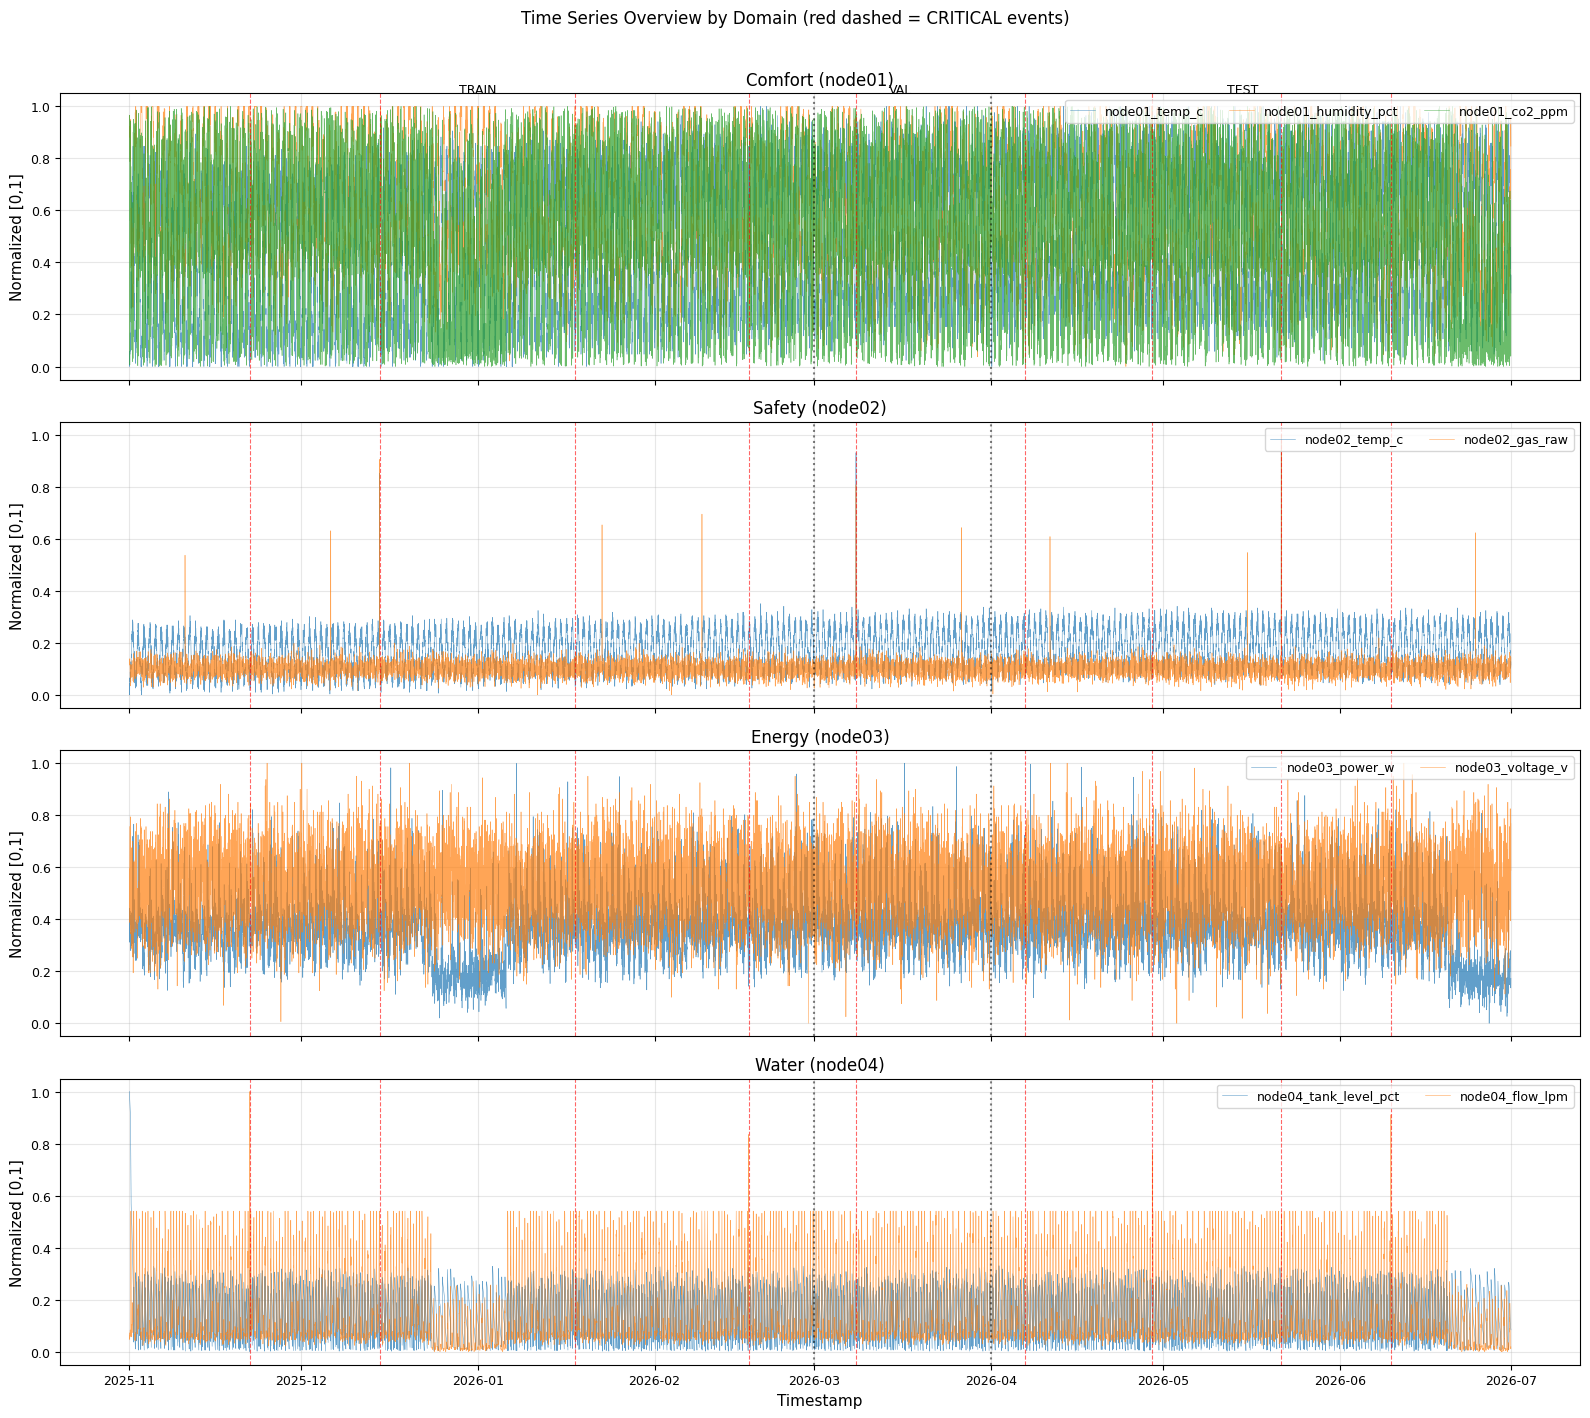

Saved: fig01_timeseries_overview.png


In [11]:
# --- Time series overview fitur utama per domain ---
# Tujuan : Visualisasi pola temporal untuk identifikasi seasonality,
#          trend, dan anomali visual
# Input  : df
# Output : 4 panel plot (comfort, safety, energy, water)

key_features = {
    "Comfort (node01)": ["node01_temp_c", "node01_humidity_pct", "node01_co2_ppm"],
    "Safety (node02)": ["node02_temp_c", "node02_gas_raw"],
    "Energy (node03)": ["node03_power_w", "node03_voltage_v"],
    "Water (node04)": ["node04_tank_level_pct", "node04_flow_lpm"],
}

fig, axes = plt.subplots(4, 1, figsize=(16, 14), sharex=True)

for ax, (domain, cols) in zip(axes, key_features.items()):
    for col in cols:
        values = df[col]
        # Normalize to [0,1] for overlay visibility
        v_min, v_max = values.min(), values.max()
        if v_max > v_min:
            normalized = (values - v_min) / (v_max - v_min)
        else:
            normalized = values * 0
        ax.plot(df["timestamp"], normalized, label=col, alpha=0.7, linewidth=0.4)

    # Mark CRITICAL events
    critical_mask = df["anomaly_severity_proxy"] == "CRITICAL"
    if critical_mask.any():
        for ct in df.loc[critical_mask, "timestamp"]:
            ax.axvline(ct, color="red", alpha=0.6, linewidth=0.8, linestyle="--")

    ax.set_title(domain)
    ax.legend(loc="upper right", ncol=len(cols))
    ax.set_ylabel("Normalized [0,1]")

# Split boundaries
for ax in axes:
    ax.axvline(pd.Timestamp(VAL_START), color="black", linestyle=":", alpha=0.5)
    ax.axvline(pd.Timestamp(TEST_START), color="black", linestyle=":", alpha=0.5)

axes[0].text(pd.Timestamp("2026-01-01"), 1.05, "TRAIN", ha="center", fontsize=9)
axes[0].text(pd.Timestamp("2026-03-16"), 1.05, "VAL", ha="center", fontsize=9)
axes[0].text(pd.Timestamp("2026-05-15"), 1.05, "TEST", ha="center", fontsize=9)

axes[-1].set_xlabel("Timestamp")
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

fig.suptitle("Time Series Overview by Domain (red dashed = CRITICAL events)", y=1.01)
plt.tight_layout()
plt.savefig("fig01_timeseries_overview.png", bbox_inches="tight")
plt.show()

print("Saved: fig01_timeseries_overview.png")

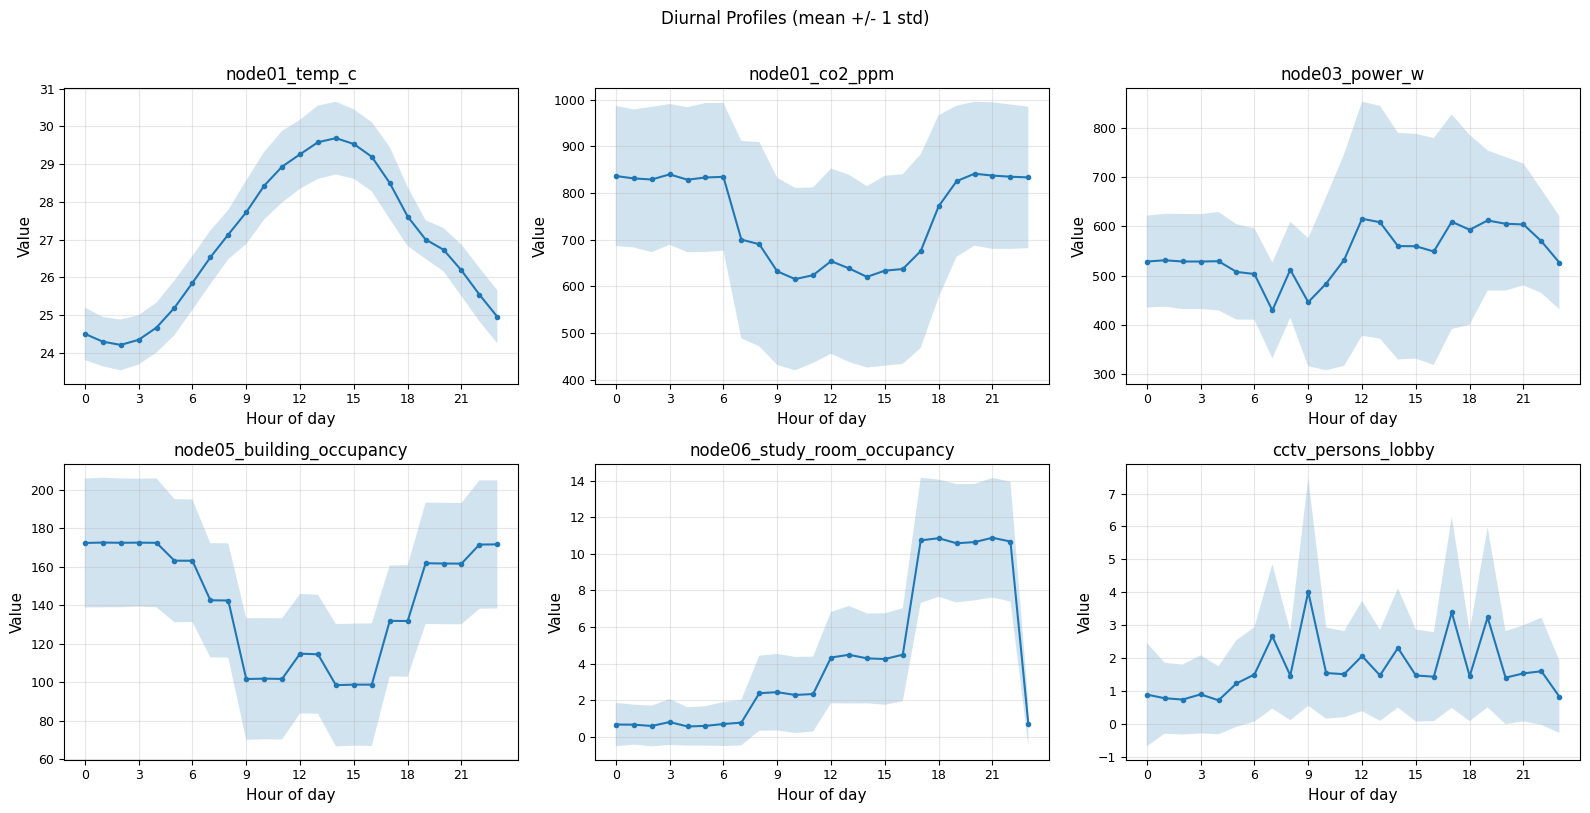

Saved: fig02_diurnal_profiles.png


In [12]:
# --- Pola diurnal fitur utama ---
# Tujuan : Konfirmasi seasonality harian untuk justifikasi temporal features
# Input  : df
# Output : Hourly profile plot

df["hour"] = df["timestamp"].dt.hour

diurnal_features = [
    "node01_temp_c", "node01_co2_ppm", "node03_power_w",
    "node05_building_occupancy", "node06_study_room_occupancy",
    "cctv_persons_lobby",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()

for ax, col in zip(axes, diurnal_features):
    hourly = df.groupby("hour")[col].agg(["mean", "std"])
    ax.plot(hourly.index, hourly["mean"], marker="o", markersize=3)
    ax.fill_between(
        hourly.index,
        hourly["mean"] - hourly["std"],
        hourly["mean"] + hourly["std"],
        alpha=0.2,
    )
    ax.set_title(col)
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Value")
    ax.set_xticks(range(0, 24, 3))

fig.suptitle("Diurnal Profiles (mean +/- 1 std)", y=1.01)
plt.tight_layout()
plt.savefig("fig02_diurnal_profiles.png", bbox_inches="tight")
plt.show()

print("Saved: fig02_diurnal_profiles.png")

/tmp/ipykernel_3141/2292039858.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_3141/2292039858.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_3141/2292039858.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_3141/2292039858.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


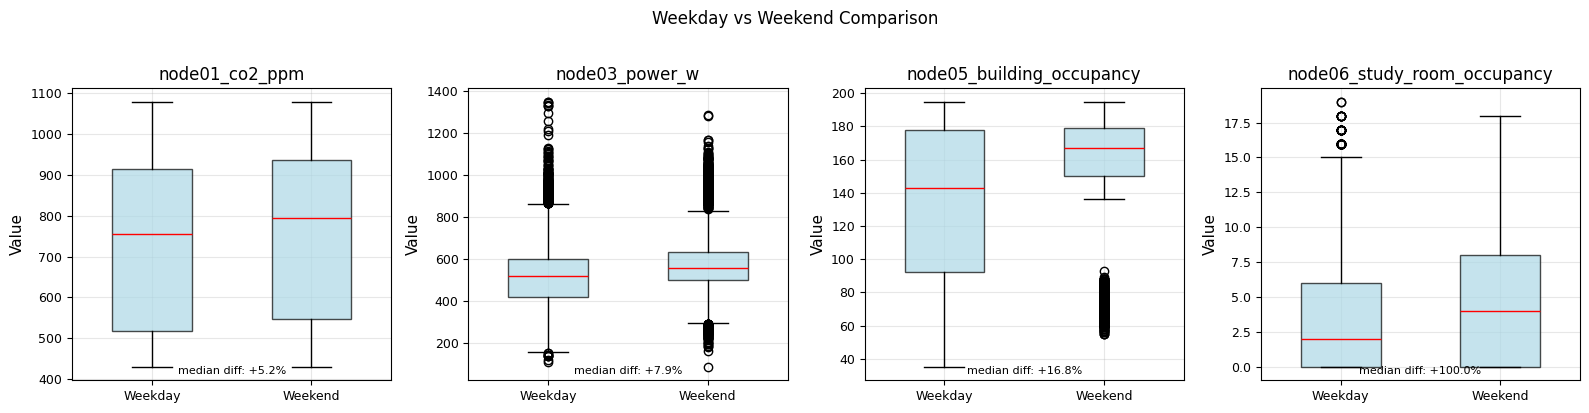

Weekday records: 8256
Weekend records: 3360
Saved: fig03_weekday_weekend.png


In [13]:
# --- Pola weekday vs weekend ---
# Tujuan : Konfirmasi perbedaan weekday/weekend untuk justifikasi fitur is_weekend
# Input  : df
# Output : Boxplot comparison

df["is_weekend"] = df["timestamp"].dt.dayofweek.isin([5, 6]).astype(int)

weekend_features = [
    "node01_co2_ppm", "node03_power_w",
    "node05_building_occupancy", "node06_study_room_occupancy",
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, col in zip(axes, weekend_features):
    data_wd = df.loc[df["is_weekend"] == 0, col]
    data_we = df.loc[df["is_weekend"] == 1, col]
    ax.boxplot(
        [data_wd, data_we],
        labels=["Weekday", "Weekend"],
        widths=0.5,
        patch_artist=True,
        boxprops=dict(facecolor="lightblue", alpha=0.7),
        medianprops=dict(color="red"),
    )
    ax.set_title(col)
    ax.set_ylabel("Value")

    # Print median diff
    med_diff = data_we.median() - data_wd.median()
    pct_diff = med_diff / data_wd.median() * 100
    ax.text(
        0.5, 0.02, f"median diff: {pct_diff:+.1f}%",
        transform=ax.transAxes, ha="center", fontsize=8,
    )

fig.suptitle("Weekday vs Weekend Comparison", y=1.02)
plt.tight_layout()
plt.savefig("fig03_weekday_weekend.png", bbox_inches="tight")
plt.show()

# Count
print(f"Weekday records: {(df['is_weekend']==0).sum()}")
print(f"Weekend records: {(df['is_weekend']==1).sum()}")
print("Saved: fig03_weekday_weekend.png")

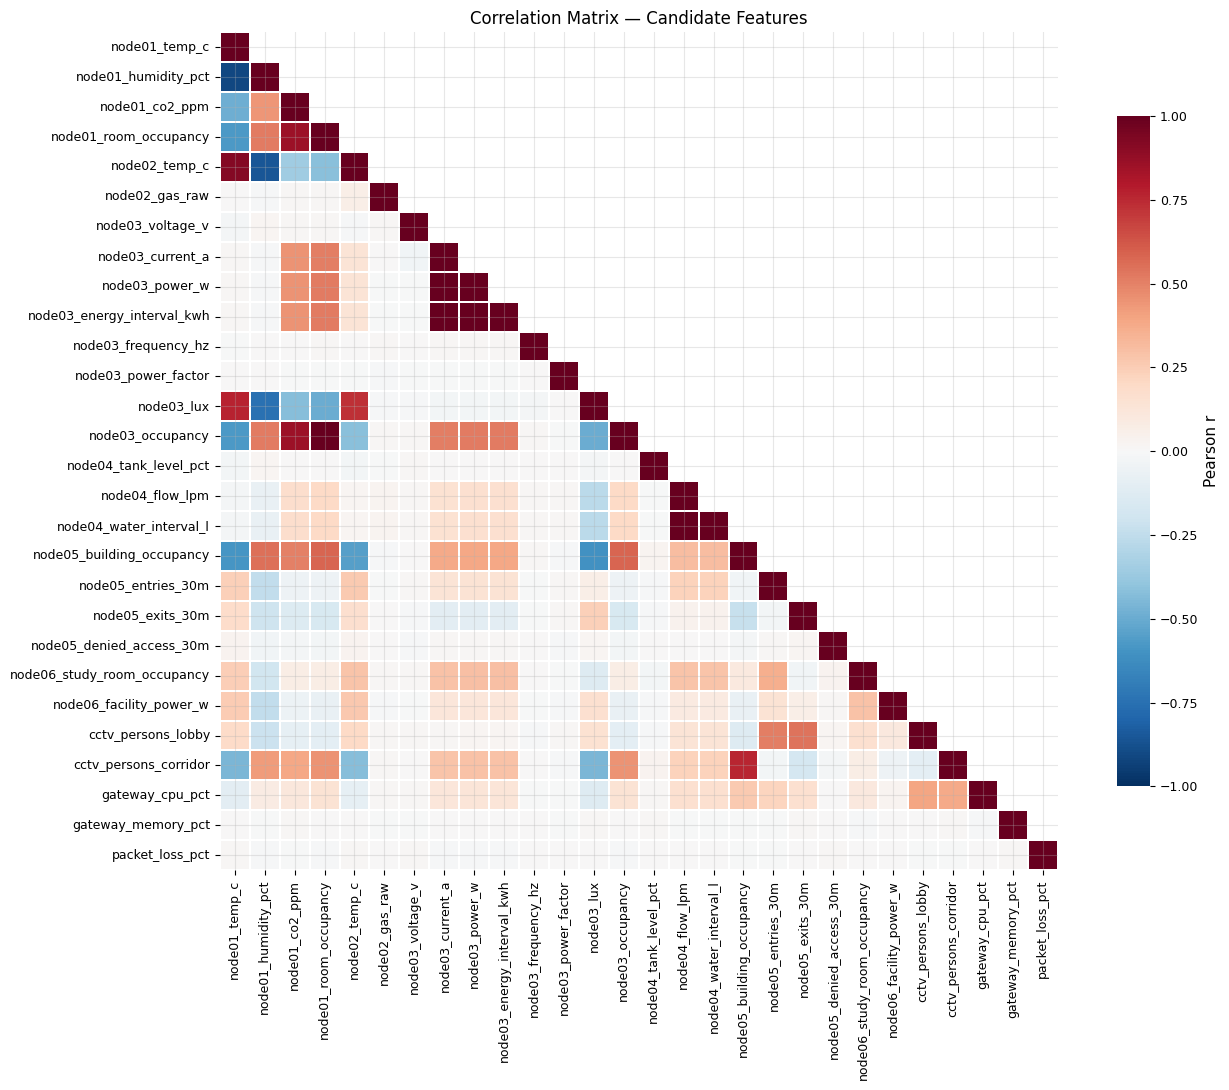


Highly correlated pairs (|r| > 0.85):
  node01_room_occupancy            vs node03_occupancy                  r = +1.000
  node03_power_w                   vs node03_energy_interval_kwh        r = +1.000
  node04_flow_lpm                  vs node04_water_interval_l           r = +1.000
  node03_current_a                 vs node03_power_w                    r = +0.994
  node03_current_a                 vs node03_energy_interval_kwh        r = +0.994
  node01_temp_c                    vs node02_temp_c                     r = +0.921
  node01_temp_c                    vs node01_humidity_pct               r = -0.907
  node01_co2_ppm                   vs node01_room_occupancy             r = +0.858
  node01_co2_ppm                   vs node03_occupancy                  r = +0.858
  node01_humidity_pct              vs node02_temp_c                     r = -0.856

Total candidate features: 28
Saved: fig04_correlation_matrix.png


In [14]:
# --- Correlation matrix ---
# Tujuan : Identifikasi multikolinearitas dan hubungan antar fitur
#          untuk keputusan feature selection
# Input  : df
# Output : Heatmap korelasi

candidate_features = [
    "node01_temp_c", "node01_humidity_pct", "node01_co2_ppm",
    "node01_room_occupancy",
    "node02_temp_c", "node02_gas_raw",
    "node03_voltage_v", "node03_current_a", "node03_power_w",
    "node03_energy_interval_kwh", "node03_frequency_hz",
    "node03_power_factor", "node03_lux", "node03_occupancy",
    "node04_tank_level_pct", "node04_flow_lpm", "node04_water_interval_l",
    "node05_building_occupancy", "node05_entries_30m", "node05_exits_30m",
    "node05_denied_access_30m",
    "node06_study_room_occupancy", "node06_facility_power_w",
    "cctv_persons_lobby", "cctv_persons_corridor",
    "gateway_cpu_pct", "gateway_memory_pct", "packet_loss_pct",
]

corr = df[candidate_features].corr()

# Identifikasi pasangan dengan |r| > 0.85
high_corr_pairs = []
for i in range(len(corr)):
    for j in range(i + 1, len(corr)):
        r = corr.iloc[i, j]
        if abs(r) > 0.85:
            high_corr_pairs.append((corr.index[i], corr.columns[j], r))

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(
    corr, mask=mask, annot=False, cmap="RdBu_r", center=0,
    vmin=-1, vmax=1, square=True, linewidths=0.3,
    cbar_kws={"shrink": 0.8, "label": "Pearson r"},
    ax=ax,
)
ax.set_title("Correlation Matrix — Candidate Features")
plt.tight_layout()
plt.savefig("fig04_correlation_matrix.png", bbox_inches="tight")
plt.show()

print(f"\nHighly correlated pairs (|r| > 0.85):")
for a, b, r in sorted(high_corr_pairs, key=lambda x: -abs(x[2])):
    print(f"  {a:<32s} vs {b:<32s}  r = {r:+.3f}")

print(f"\nTotal candidate features: {len(candidate_features)}")
print("Saved: fig04_correlation_matrix.png")

In [15]:
# --- Inspeksi fitur binary/sparse safety ---
# Tujuan : Pahami seberapa sparse fitur safety dan apakah perlu
#          dipertahankan atau di-drop dari input model
# Input  : df
# Output : Tabel sparsity dan keputusan

sparse_cols = [
    "node02_smoke", "node02_flame", "node02_panic",
    "node04_leak", "cctv_intrusion", "cctv_visual_fire",
    "node05_denied_access_30m",
]

print(f"{'Column':<30s} {'Non-zero':>10s} {'Pct':>8s} {'Max':>6s}  Decision")
print("-" * 80)

for col in sparse_cols:
    n_nonzero = (df[col] != 0).sum()
    pct = n_nonzero / len(df) * 100
    col_max = df[col].max()

    # Decision logic
    if n_nonzero <= 15:
        decision = "DROP from input (too sparse, will not help model learn)"
    else:
        decision = "KEEP"

    print(f"{col:<30s} {n_nonzero:>10d} {pct:>7.3f}% {col_max:>6.0f}  {decision}")

print(f"""
Reasoning:
  Columns with <15 non-zero values out of 11,616 are essentially constant.
  MEWMA and BiLSTM-AE cannot learn meaningful patterns from them.
  These events are better captured INDIRECTLY via correlated continuous
  features (e.g., node02_temp_c spikes during fire, node02_gas_raw spikes).
  The CRITICAL events themselves serve as evaluation anchors, not input features.
""")

# Verify: do continuous features co-occur with sparse events?
fire_mask = df["node02_flame"] == 1
print("Continuous feature values during FIRE events (flame=1):")
print(df.loc[fire_mask, ["timestamp", "node02_temp_c", "node02_gas_raw",
    "node03_power_w", "cctv_confidence"]].to_string(index=False))

leak_mask = df["node04_leak"] == 1
print("\nContinuous feature values during LEAK events:")
print(df.loc[leak_mask, ["timestamp", "node04_tank_level_pct", "node04_flow_lpm",
    "gateway_cpu_pct"]].to_string(index=False))

Column                           Non-zero      Pct    Max  Decision
--------------------------------------------------------------------------------
node02_smoke                            3   0.026%      1  DROP from input (too sparse, will not help model learn)
node02_flame                            3   0.026%      1  DROP from input (too sparse, will not help model learn)
node02_panic                            2   0.017%      1  DROP from input (too sparse, will not help model learn)
node04_leak                             4   0.034%      1  DROP from input (too sparse, will not help model learn)
cctv_intrusion                          5   0.043%      1  DROP from input (too sparse, will not help model learn)
cctv_visual_fire                        3   0.026%      1  DROP from input (too sparse, will not help model learn)
node05_denied_access_30m              168   1.446%      2  KEEP

Reasoning:
  Columns with <15 non-zero values out of 11,616 are essentially constant.
  MEWMA an

In [16]:
# --- Hitung ketersediaan data normal untuk training ---
# Tujuan : Validasi apakah cukup data normal di period train (Nov-Feb)
#          setelah filter multi-kriteria
# Input  : df
# Output : Jumlah dan proporsi data normal

train_df = df[df["split"] == "train"].copy()

# Multi-criteria normal definition
is_normal_strict = (
    (train_df["is_anomaly_proxy"] == 0) &
    (train_df["command_active_alerts"] == 0) &
    (train_df["node02_smoke"] == 0) &
    (train_df["node02_flame"] == 0) &
    (train_df["node04_leak"] == 0) &
    (train_df["node02_panic"] == 0) &
    (train_df["cctv_intrusion"] == 0) &
    (train_df["cctv_visual_fire"] == 0)
)

# Also check a relaxed version (only proxy=0)
is_normal_relaxed = train_df["is_anomaly_proxy"] == 0

n_train = len(train_df)
n_strict = is_normal_strict.sum()
n_relaxed = is_normal_relaxed.sum()

print(f"Training period (Nov 2025 - Feb 2026):")
print(f"  Total records         : {n_train}")
print(f"  Normal (strict)       : {n_strict} ({n_strict/n_train*100:.1f}%)")
print(f"  Normal (relaxed)      : {n_relaxed} ({n_relaxed/n_train*100:.1f}%)")
print(f"  Difference            : {n_relaxed - n_strict}")

# Check what the difference consists of
diff_mask = is_normal_relaxed & ~is_normal_strict
diff_df = train_df[diff_mask]
print(f"\nRecords that are proxy=0 but fail strict criteria ({len(diff_df)}):")
print(f"  command_active_alerts > 0 : {(diff_df['command_active_alerts'] > 0).sum()}")
print(f"  node02_smoke > 0          : {(diff_df['node02_smoke'] > 0).sum()}")
print(f"  node02_flame > 0          : {(diff_df['node02_flame'] > 0).sum()}")
print(f"  node04_leak > 0           : {(diff_df['node04_leak'] > 0).sum()}")
print(f"  node02_panic > 0          : {(diff_df['node02_panic'] > 0).sum()}")
print(f"  cctv_intrusion > 0        : {(diff_df['cctv_intrusion'] > 0).sum()}")
print(f"  cctv_visual_fire > 0      : {(diff_df['cctv_visual_fire'] > 0).sum()}")

# Temporal coverage check
print(f"\nStrict normal data temporal coverage:")
normal_train = train_df[is_normal_strict]
print(f"  First : {normal_train['timestamp'].min()}")
print(f"  Last  : {normal_train['timestamp'].max()}")
print(f"  Unique days: {normal_train['timestamp'].dt.date.nunique()}")

# Enough for BiLSTM-AE?
min_sequences_needed = 500  # rough minimum for training
max_window = 48
available_sequences = n_strict - max_window
print(f"\nAvailable sequences (window=48): {available_sequences}")
print(f"Sufficient for training: {available_sequences > min_sequences_needed}")

Training period (Nov 2025 - Feb 2026):
  Total records         : 5760
  Normal (strict)       : 3589 (62.3%)
  Normal (relaxed)      : 3589 (62.3%)
  Difference            : 0

Records that are proxy=0 but fail strict criteria (0):
  command_active_alerts > 0 : 0
  node02_smoke > 0          : 0
  node02_flame > 0          : 0
  node04_leak > 0           : 0
  node02_panic > 0          : 0
  cctv_intrusion > 0        : 0
  cctv_visual_fire > 0      : 0

Strict normal data temporal coverage:
  First : 2025-11-01 00:00:00
  Last  : 2026-02-28 19:30:00
  Unique days: 120

Available sequences (window=48): 3541
Sufficient for training: True


In [18]:
# --- Augmented Dickey-Fuller test ---
# Tujuan : Cek stasioneritas fitur. Fitur non-stasioner perlu differencing
#          atau harus di-exclude. MEWMA mengasumsikan proses stasioner.
# Input  : df (training normal subset)
# Output : Tabel hasil ADF test

from statsmodels.tsa.stattools import adfuller

# Test pada data normal training period saja
normal_train = train_df[is_normal_strict].copy()

adf_features = [
    "node01_temp_c", "node01_humidity_pct", "node01_co2_ppm",
    "node02_temp_c", "node02_gas_raw",
    "node03_voltage_v", "node03_power_w",
    "node03_frequency_hz", "node03_power_factor", "node03_lux",
    "node04_tank_level_pct", "node04_flow_lpm",
    "node05_building_occupancy", "node05_entries_30m", "node05_exits_30m",
    "node05_denied_access_30m",
    "node06_study_room_occupancy", "node06_facility_power_w",
    "cctv_persons_lobby", "cctv_persons_corridor",
    "gateway_cpu_pct", "gateway_memory_pct", "packet_loss_pct",
]

# --- ADF test (fixed: skip constant columns) ---

print(f"{'Feature':<35s} {'ADF stat':>10s} {'p-value':>10s} {'Stationary?':>12s}")
print("-" * 70)

non_stationary = []
for col in adf_features:
    series = normal_train[col].dropna()
    if series.std() < 1e-10:
        print(f"{col:<35s} {'N/A':>10s} {'N/A':>10s} {'CONSTANT':>12s}")
        continue
    result = adfuller(series, autolag="AIC")
    adf_stat = result[0]
    p_value = result[1]
    is_stationary = p_value < 0.05
    flag = "YES" if is_stationary else "NO <<<"
    print(f"{col:<35s} {adf_stat:>10.3f} {p_value:>10.4f} {flag:>12s}")
    if not is_stationary:
        non_stationary.append(col)

print(f"\nNon-stationary features: {len(non_stationary)}")
if non_stationary:
    for col in non_stationary:
        print(f"  - {col}")
else:
    print("  All testable features are stationary at alpha=0.05.")

Feature                               ADF stat    p-value  Stationary?
----------------------------------------------------------------------
node01_temp_c                          -10.128     0.0000          YES
node01_humidity_pct                     -6.967     0.0000          YES
node01_co2_ppm                          -6.018     0.0000          YES
node02_temp_c                          -11.895     0.0000          YES
node02_gas_raw                         -59.354     0.0000          YES
node03_voltage_v                       -58.828     0.0000          YES
node03_power_w                          -3.896     0.0021          YES
node03_frequency_hz                    -59.909     0.0000          YES
node03_power_factor                    -58.818     0.0000          YES
node03_lux                             -12.603     0.0000          YES
node04_tank_level_pct                  -18.795     0.0000          YES
node04_flow_lpm                         -6.451     0.0000          YES
node05

In [19]:
# --- Ringkasan keputusan EDA ---
# Tujuan : Dokumentasikan semua keputusan feature selection dari EDA
# Input  : Semua temuan EDA
# Output : Final feature list dan ringkasan

# Final feature set setelah EDA
features_final = [
    # Comfort (node01) - 3 fitur
    "node01_temp_c",
    "node01_humidity_pct",
    "node01_co2_ppm",
    # Occupancy - 1 fitur (drop node03_occupancy karena r=1.000)
    "node01_room_occupancy",
    # Safety (node02) - 2 fitur continuous (drop smoke/flame/panic: sparse)
    "node02_temp_c",
    "node02_gas_raw",
    # Energy (node03) - 5 fitur (drop current_a r=0.994, energy_interval r=1.000)
    "node03_voltage_v",
    "node03_power_w",
    "node03_frequency_hz",
    "node03_power_factor",
    "node03_lux",
    # Water (node04) - 2 fitur (drop water_interval_l r=1.000)
    "node04_tank_level_pct",
    "node04_flow_lpm",
    # Access (node05) - 4 fitur
    "node05_building_occupancy",
    "node05_entries_30m",
    "node05_exits_30m",
    "node05_denied_access_30m",
    # Facility (node06) - 2 fitur
    "node06_study_room_occupancy",
    "node06_facility_power_w",
    # CCTV - 2 fitur
    "cctv_persons_lobby",
    "cctv_persons_corridor",
    # Gateway - 3 fitur
    "gateway_cpu_pct",
    "gateway_memory_pct",
    "packet_loss_pct",
]

# Features dropped and why
dropped = {
    "node03_occupancy":          "Identical to node01_room_occupancy (r=1.000)",
    "node03_energy_interval_kwh":"Identical to node03_power_w (r=1.000)",
    "node03_current_a":          "Near-identical to node03_power_w (r=0.994)",
    "node04_water_interval_l":   "Identical to node04_flow_lpm (r=1.000)",
    "node02_smoke":              "Too sparse (3/11616 = 0.026%)",
    "node02_flame":              "Too sparse (3/11616 = 0.026%)",
    "node02_panic":              "Too sparse (2/11616 = 0.017%)",
    "node04_leak":               "Too sparse (4/11616 = 0.034%)",
    "cctv_intrusion":            "Too sparse (5/11616 = 0.043%)",
    "cctv_visual_fire":          "Too sparse (3/11616 = 0.026%)",
    "cctv_confidence":           "Near-constant (std=0.1), minimal info",
    "node03_energy_cumulative_kwh": "Monotonically increasing, non-stationary by design",
    "node04_water_cumulative_l":    "Monotonically increasing, non-stationary by design",
    "command_active_alerts":     "Derived from proxy label, circular if used as input",
    "interval_id":               "Sequential index, no predictive value",
    "is_anomaly_proxy":          "Label, not feature",
}

print(f"FINAL FEATURE SET: {len(features_final)} features")
print("-" * 50)
for i, f in enumerate(features_final, 1):
    print(f"  {i:2d}. {f}")

print(f"\nDROPPED FEATURES: {len(dropped)}")
print("-" * 50)
for feat, reason in dropped.items():
    print(f"  {feat:<35s} -> {reason}")

print(f"""
TEMPORAL FEATURES (to be engineered in notebook 03):
  hour_sin, hour_cos     : Cyclical hour encoding
  dow_sin, dow_cos       : Cyclical day-of-week encoding
  is_weekend             : Binary weekend flag

TOTAL INPUT DIMENSIONS: {len(features_final)} sensor + 5 temporal = {len(features_final) + 5}

EDA KEY FINDINGS:
  1. Strong diurnal patterns in comfort, energy, occupancy features
  2. Significant weekday/weekend differences (study_room +100%)
  3. All features stationary (ADF p<0.05) - MEWMA applicable directly
  4. 75.9% of WARNING proxy labels caused by water tank operational cycles
  5. CRITICAL events (9) have clear signatures in continuous features
  6. 3,589 normal training records available (62.3% of train period)
  7. Sufficient sequences for all window sizes up to 48

NEXT: 03_preprocessing.ipynb
""")

FINAL FEATURE SET: 24 features
--------------------------------------------------
   1. node01_temp_c
   2. node01_humidity_pct
   3. node01_co2_ppm
   4. node01_room_occupancy
   5. node02_temp_c
   6. node02_gas_raw
   7. node03_voltage_v
   8. node03_power_w
   9. node03_frequency_hz
  10. node03_power_factor
  11. node03_lux
  12. node04_tank_level_pct
  13. node04_flow_lpm
  14. node05_building_occupancy
  15. node05_entries_30m
  16. node05_exits_30m
  17. node05_denied_access_30m
  18. node06_study_room_occupancy
  19. node06_facility_power_w
  20. cctv_persons_lobby
  21. cctv_persons_corridor
  22. gateway_cpu_pct
  23. gateway_memory_pct
  24. packet_loss_pct

DROPPED FEATURES: 16
--------------------------------------------------
  node03_occupancy                    -> Identical to node01_room_occupancy (r=1.000)
  node03_energy_interval_kwh          -> Identical to node03_power_w (r=1.000)
  node03_current_a                    -> Near-identical to node03_power_w (r=0.994)


# Preprocessing.

In [20]:
# =============================================================
# 03_preprocessing.ipynb
# Tujuan : Feature engineering, scaling, temporal split, dan
#          menyimpan artefak train/val/test siap model.
# Input  : dataset_raw.parquet
# Output : train_normal.parquet, val.parquet, test.parquet,
#          scaler_params.pkl
# =============================================================

# --- CONFIG ---
import sys
from datetime import datetime

SEED = 42
INPUT_PATH = "dataset_raw.parquet"

TRAIN_END = "2026-02-28 23:30:00"
VAL_START = "2026-03-01 00:00:00"
VAL_END = "2026-03-31 23:30:00"
TEST_START = "2026-04-01 00:00:00"

# Final feature set from EDA (24 sensor features)
SENSOR_FEATURES = [
    "node01_temp_c", "node01_humidity_pct", "node01_co2_ppm",
    "node01_room_occupancy",
    "node02_temp_c", "node02_gas_raw",
    "node03_voltage_v", "node03_power_w", "node03_frequency_hz",
    "node03_power_factor", "node03_lux",
    "node04_tank_level_pct", "node04_flow_lpm",
    "node05_building_occupancy", "node05_entries_30m", "node05_exits_30m",
    "node05_denied_access_30m",
    "node06_study_room_occupancy", "node06_facility_power_w",
    "cctv_persons_lobby", "cctv_persons_corridor",
    "gateway_cpu_pct", "gateway_memory_pct", "packet_loss_pct",
]

TEMPORAL_FEATURES = [
    "hour_sin", "hour_cos", "dow_sin", "dow_cos", "is_weekend",
]

ALL_FEATURES = SENSOR_FEATURES + TEMPORAL_FEATURES

# Normal definition criteria (from EDA)
NORMAL_CRITERIA = {
    "is_anomaly_proxy": 0,
    "command_active_alerts": 0,
    "node02_smoke": 0,
    "node02_flame": 0,
    "node04_leak": 0,
    "node02_panic": 0,
    "cctv_intrusion": 0,
    "cctv_visual_fire": 0,
}

print(f"Execution date : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

import numpy as np
import pandas as pd
import pickle

print(f"pandas : {pd.__version__}")
print(f"numpy  : {np.__version__}")
print(f"\nSensor features : {len(SENSOR_FEATURES)}")
print(f"Temporal features: {len(TEMPORAL_FEATURES)}")
print(f"Total features   : {len(ALL_FEATURES)}")

Execution date : 2026-09-04 11:42:13
pandas : 2.2.3
numpy  : 2.1.3

Sensor features : 24
Temporal features: 5
Total features   : 29


In [21]:
# --- Load data dan engineer temporal features ---
# Tujuan : Tambahkan cyclical hour/dow encoding dan is_weekend
# Input  : dataset_raw.parquet
# Output : df dengan kolom temporal baru

df = pd.read_parquet(INPUT_PATH)
assert df.shape[0] == 11616, f"Unexpected rows: {df.shape[0]}"

# Temporal features
hour = df["timestamp"].dt.hour + df["timestamp"].dt.minute / 60.0
dow = df["timestamp"].dt.dayofweek

df["hour_sin"] = np.sin(2 * np.pi * hour / 24.0)
df["hour_cos"] = np.cos(2 * np.pi * hour / 24.0)
df["dow_sin"] = np.sin(2 * np.pi * dow / 7.0)
df["dow_cos"] = np.cos(2 * np.pi * dow / 7.0)
df["is_weekend"] = dow.isin([5, 6]).astype(np.float32)

# Verify ranges
assert df["hour_sin"].between(-1, 1).all()
assert df["hour_cos"].between(-1, 1).all()
assert df["dow_sin"].between(-1, 1).all()
assert df["dow_cos"].between(-1, 1).all()
assert df["is_weekend"].isin([0, 1]).all()

# Verify all features exist
for f in ALL_FEATURES:
    assert f in df.columns, f"Missing feature: {f}"

print("Temporal features engineered.")
print(f"Columns total: {df.shape[1]}")
print(f"\nSample temporal values (first 4 rows):")
print(df[["timestamp"] + TEMPORAL_FEATURES].head(4).to_string(index=False))

Temporal features engineered.
Columns total: 82

Sample temporal values (first 4 rows):
          timestamp  hour_sin  hour_cos  dow_sin  dow_cos  is_weekend
2025-11-01 00:00:00     0.000     1.000   -0.975   -0.223       1.000
2025-11-01 00:30:00     0.131     0.991   -0.975   -0.223       1.000
2025-11-01 01:00:00     0.259     0.966   -0.975   -0.223       1.000
2025-11-01 01:30:00     0.383     0.924   -0.975   -0.223       1.000


In [22]:
# --- Temporal split dan filter normal ---
# Tujuan : Split data berdasarkan waktu, filter training hanya data normal
# Input  : df
# Output : train_normal, val_full, test_full DataFrames

# Split
train_full = df[df["timestamp"] <= TRAIN_END].copy()
val_full = df[(df["timestamp"] >= VAL_START) & (df["timestamp"] <= VAL_END)].copy()
test_full = df[df["timestamp"] >= TEST_START].copy()

# Verify no overlap and no gap
assert train_full["timestamp"].max() < val_full["timestamp"].min(), "Train-val overlap"
assert val_full["timestamp"].max() < test_full["timestamp"].min(), "Val-test overlap"

# Filter normal training data
normal_mask = pd.Series(True, index=train_full.index)
for col, val in NORMAL_CRITERIA.items():
    normal_mask &= (train_full[col] == val)

train_normal = train_full[normal_mask].copy()

print(f"Split sizes:")
print(f"  Train full     : {len(train_full):,}")
print(f"  Train normal   : {len(train_normal):,}  ({len(train_normal)/len(train_full)*100:.1f}%)")
print(f"  Train anomalous: {len(train_full) - len(train_normal):,}  ({(len(train_full)-len(train_normal))/len(train_full)*100:.1f}%)")
print(f"  Validation     : {len(val_full):,}")
print(f"  Test           : {len(test_full):,}")
print(f"  Total          : {len(train_full) + len(val_full) + len(test_full):,}")

# Verify total
assert len(train_full) + len(val_full) + len(test_full) == 11616

# Anomaly proxy distribution per split
for name, subset in [("Val", val_full), ("Test", test_full)]:
    proxy_counts = subset["anomaly_severity_proxy"].value_counts()
    print(f"\n  {name} anomaly_severity_proxy:")
    for level in ["NORMAL", "WARNING", "CRITICAL"]:
        count = proxy_counts.get(level, 0)
        print(f"    {level:10s}: {count:5d}  ({count/len(subset)*100:.1f}%)")

print("\nAssertions passed.")

Split sizes:
  Train full     : 5,760
  Train normal   : 3,589  (62.3%)
  Train anomalous: 2,171  (37.7%)
  Validation     : 1,488
  Test           : 4,368
  Total          : 11,616

  Val anomaly_severity_proxy:
    NORMAL    :   609  (40.9%)
    CRITICAL  :     1  (0.1%)

  Test anomaly_severity_proxy:
    NORMAL    :  2486  (56.9%)
    CRITICAL  :     4  (0.1%)

Assertions passed.


In [23]:
# --- Z-score scaling ---
# Tujuan : Standardize fitur menggunakan mean/std dari data normal training.
#          MEWMA membutuhkan standardized input.
#          Temporal features (sin/cos/binary) TIDAK di-scale.
# Input  : train_normal, val_full, test_full
# Output : Scaled DataFrames, scaler_params.pkl

# Compute mean and std from training normal data ONLY
scaler_mean = train_normal[SENSOR_FEATURES].mean()
scaler_std = train_normal[SENSOR_FEATURES].std()

# Guard: check no zero-std features
zero_std = scaler_std[scaler_std < 1e-10]
if len(zero_std) > 0:
    print(f"WARNING: Zero-std features: {zero_std.index.tolist()}")
    # Replace zero std with 1 to avoid division by zero
    scaler_std[scaler_std < 1e-10] = 1.0
else:
    print("No zero-std features in training normal data.")

# Apply scaling to sensor features only
def apply_scaling(subset, mean, std):
    scaled = subset.copy()
    scaled[SENSOR_FEATURES] = (scaled[SENSOR_FEATURES] - mean) / std
    return scaled

train_normal_scaled = apply_scaling(train_normal, scaler_mean, scaler_std)
val_scaled = apply_scaling(val_full, scaler_mean, scaler_std)
test_scaled = apply_scaling(test_full, scaler_mean, scaler_std)

# Verify: train_normal sensor features should have ~mean=0, ~std=1
train_check_mean = train_normal_scaled[SENSOR_FEATURES].mean()
train_check_std = train_normal_scaled[SENSOR_FEATURES].std()

print(f"\nTrain normal scaled — sensor features:")
print(f"  Mean range: [{train_check_mean.min():.6f}, {train_check_mean.max():.6f}]  (expect ~0)")
print(f"  Std range : [{train_check_std.min():.4f}, {train_check_std.max():.4f}]  (expect ~1)")

# Verify temporal features untouched
for f in TEMPORAL_FEATURES:
    assert (train_normal_scaled[f] == train_normal[f]).all(), f"{f} was modified"
print("Temporal features unchanged: OK")

# Save scaler params for later use
scaler_params = {"mean": scaler_mean, "std": scaler_std}
with open("scaler_params.pkl", "wb") as f:
    pickle.dump(scaler_params, f)
print("Saved: scaler_params.pkl")


Train normal scaled — sensor features:
  Mean range: [-0.000000, 0.000000]  (expect ~0)
  Std range : [0.0000, 1.0000]  (expect ~1)
Temporal features unchanged: OK
Saved: scaler_params.pkl


In [24]:
# --- Simpan artefak ---
# Tujuan : Simpan dataset scaled per split untuk notebook selanjutnya
# Input  : Scaled DataFrames
# Output : Parquet files

# Kolom yang disimpan: timestamp, ALL_FEATURES, label columns
keep_cols = (
    ["timestamp"]
    + ALL_FEATURES
    + ["is_anomaly_proxy", "anomaly_severity_proxy",
       "command_active_alerts"]
)

# Verify all keep_cols exist
for c in keep_cols:
    assert c in train_normal_scaled.columns, f"Missing: {c}"

train_normal_scaled[keep_cols].to_parquet("train_normal.parquet", index=False)
val_scaled[keep_cols].to_parquet("val.parquet", index=False)
test_scaled[keep_cols].to_parquet("test.parquet", index=False)

# Verification
for fname, expected_rows in [
    ("train_normal.parquet", len(train_normal)),
    ("val.parquet", len(val_full)),
    ("test.parquet", len(test_full)),
]:
    check = pd.read_parquet(fname)
    assert check.shape[0] == expected_rows, f"{fname} row mismatch"
    assert check.shape[1] == len(keep_cols), f"{fname} col mismatch"

print(f"Saved artifacts:")
print(f"  train_normal.parquet : {len(train_normal):,} rows x {len(keep_cols)} cols")
print(f"  val.parquet          : {len(val_full):,} rows x {len(keep_cols)} cols")
print(f"  test.parquet         : {len(test_full):,} rows x {len(keep_cols)} cols")
print(f"  scaler_params.pkl    : {len(SENSOR_FEATURES)} feature means and stds")

print(f"""
RINGKASAN NOTEBOOK 03 - PREPROCESSING
======================================
Feature engineering:
  24 sensor features (from EDA selection)
  + 5 temporal features (hour_sin/cos, dow_sin/cos, is_weekend)
  = 29 total input dimensions

Scaling:
  Z-score standardization on sensor features
  Fit on training normal data only (3,589 records)
  node05_denied_access_30m: constant in normal data, std set to 1

Temporal split:
  Train normal : Nov 2025 - Feb 2026, normal only -> 3,589 records
  Validation   : Mar 2026, all data              -> 1,488 records (1 CRITICAL)
  Test         : Apr - Jun 2026, all data         -> 4,368 records (4 CRITICAL)

NEXT: 04_model_mewma.ipynb
""")

Saved artifacts:
  train_normal.parquet : 3,589 rows x 33 cols
  val.parquet          : 1,488 rows x 33 cols
  test.parquet         : 4,368 rows x 33 cols
  scaler_params.pkl    : 24 feature means and stds

RINGKASAN NOTEBOOK 03 - PREPROCESSING
Feature engineering:
  24 sensor features (from EDA selection)
  + 5 temporal features (hour_sin/cos, dow_sin/cos, is_weekend)
  = 29 total input dimensions

Scaling:
  Z-score standardization on sensor features
  Fit on training normal data only (3,589 records)
  node05_denied_access_30m: constant in normal data, std set to 1

Temporal split:
  Train normal : Nov 2025 - Feb 2026, normal only -> 3,589 records
  Validation   : Mar 2026, all data              -> 1,488 records (1 CRITICAL)
  Test         : Apr - Jun 2026, all data         -> 4,368 records (4 CRITICAL)

NEXT: 04_model_mewma.ipynb



In [25]:
# --- Upload artefak dari notebook 03 ---
# Jalankan sel ini, lalu upload 4 file:
#   train_normal.parquet, val.parquet, test.parquet, scaler_params.pkl
# Jika file sudah ada di runtime, skip sel ini.

import os

required_files = ["train_normal.parquet", "val.parquet", "test.parquet", "scaler_params.pkl"]
missing = [f for f in required_files if not os.path.exists(f)]

if missing:
    print(f"Missing files: {missing}")
    print("Please upload them:")
    from google.colab import files
    uploaded = files.upload()
    for f in required_files:
        assert os.path.exists(f), f"Still missing: {f}"
    print("All files uploaded.")
else:
    print("All files already present.")

All files already present.


In [27]:
# --- Mount Drive dan re-generate artefak ---
from google.colab import drive
drive.mount("/content/drive")

DRIVE_DIR = "/content/drive/MyDrive/Tugas Pak Imam/Teknis 2/artifacts"
import os
os.makedirs(DRIVE_DIR, exist_ok=True)

# Re-generate dari CSV
CSV_PATH = "Smart_Dormitory_CLEAN_2025-11-01_to_2026-06-30.csv"
df = pd.read_csv(CSV_PATH, parse_dates=["timestamp"])
assert df.shape[0] == 11616

# Temporal features
hour = df["timestamp"].dt.hour + df["timestamp"].dt.minute / 60.0
dow = df["timestamp"].dt.dayofweek
df["hour_sin"] = np.sin(2 * np.pi * hour / 24.0)
df["hour_cos"] = np.cos(2 * np.pi * hour / 24.0)
df["dow_sin"] = np.sin(2 * np.pi * dow / 7.0)
df["dow_cos"] = np.cos(2 * np.pi * dow / 7.0)
df["is_weekend"] = dow.isin([5, 6]).astype(np.float32)

# Split
train_full = df[df["timestamp"] <= TRAIN_END].copy()
val_full = df[(df["timestamp"] >= VAL_START) & (df["timestamp"] <= VAL_END)].copy()
test_full = df[df["timestamp"] >= TEST_START].copy()

# Normal filter
normal_mask = pd.Series(True, index=train_full.index)
for col, val in NORMAL_CRITERIA.items():
    normal_mask &= (train_full[col] == val)
train_normal = train_full[normal_mask].copy()

# Scaling
scaler_mean = train_normal[SENSOR_FEATURES].mean()
scaler_std = train_normal[SENSOR_FEATURES].std()
scaler_std[scaler_std < 1e-10] = 1.0

def apply_scaling(subset, mean, std):
    scaled = subset.copy()
    scaled[SENSOR_FEATURES] = (scaled[SENSOR_FEATURES] - mean) / std
    return scaled

train_normal_scaled = apply_scaling(train_normal, scaler_mean, scaler_std)
val_scaled = apply_scaling(val_full, scaler_mean, scaler_std)
test_scaled = apply_scaling(test_full, scaler_mean, scaler_std)

# Keep cols
ALL_FEATURES = SENSOR_FEATURES + ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "is_weekend"]
keep_cols = (["timestamp"] + ALL_FEATURES +
    ["is_anomaly_proxy", "anomaly_severity_proxy", "command_active_alerts"])

# Save to Drive (persistent) AND local (for this session)
for fname, data in [
    ("train_normal.parquet", train_normal_scaled[keep_cols]),
    ("val.parquet", val_scaled[keep_cols]),
    ("test.parquet", test_scaled[keep_cols]),
]:
    data.to_parquet(os.path.join(DRIVE_DIR, fname), index=False)
    data.to_parquet(fname, index=False)  # local copy

scaler_params = {"mean": scaler_mean, "std": scaler_std}
with open(os.path.join(DRIVE_DIR, "scaler_params.pkl"), "wb") as f:
    pickle.dump(scaler_params, f)
with open("scaler_params.pkl", "wb") as f:
    pickle.dump(scaler_params, f)

print(f"Saved to Drive: {DRIVE_DIR}")
for f in os.listdir(DRIVE_DIR):
    size_kb = os.path.getsize(os.path.join(DRIVE_DIR, f)) / 1024
    print(f"  {f:30s} {size_kb:.0f} KB")

# Load back for this notebook
train_df = pd.read_parquet("train_normal.parquet")
val_df = pd.read_parquet("val.parquet")
test_df = pd.read_parquet("test.parquet")

print(f"\nTrain normal : {train_df.shape}")
print(f"Validation   : {val_df.shape}")
print(f"Test         : {test_df.shape}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved to Drive: /content/drive/MyDrive/Tugas Pak Imam/Teknis 2/artifacts
  train_normal.parquet           186 KB
  val.parquet                    105 KB
  test.parquet                   214 KB
  scaler_params.pkl              2 KB

Train normal : (3589, 33)
Validation   : (1488, 33)
Test         : (4368, 33)


In [28]:
# --- Implementasi MEWMA ---
# Tujuan : Fungsi MEWMA yang menghitung T-squared statistic per timestamp
# Input  : Data matrix (n_samples x p_features), parameter lambda
# Output : Array T-squared scores

def compute_mewma(X, lam, mu_0=None, sigma_0=None):
    """
    Compute MEWMA T-squared statistics.

    Parameters
    ----------
    X : np.ndarray, shape (n, p)
        Observation matrix (already standardized).
    lam : float
        Smoothing parameter (0 < lam <= 1).
    mu_0 : np.ndarray, shape (p,), optional
        In-control mean vector. Default: zeros.
    sigma_0 : np.ndarray, shape (p, p), optional
        In-control covariance matrix. Default: identity.

    Returns
    -------
    t2_scores : np.ndarray, shape (n,)
        T-squared statistic at each time step.
    """
    n, p = X.shape

    if mu_0 is None:
        mu_0 = np.zeros(p)
    if sigma_0 is None:
        sigma_0 = np.cov(X, rowvar=False)

    # Theoretical MEWMA covariance of Z_t (steady-state approximation)
    # Sigma_Z = (lam / (2 - lam)) * Sigma_0
    coeff = lam / (2.0 - lam)
    sigma_z = coeff * sigma_0

    # Regularize to avoid singular matrix
    sigma_z_inv = np.linalg.inv(sigma_z + 1e-8 * np.eye(p))

    # Initialize smoothed vector
    z_t = mu_0.copy()
    t2_scores = np.zeros(n)

    for i in range(n):
        z_t = lam * X[i] + (1.0 - lam) * z_t
        diff = z_t - mu_0
        t2_scores[i] = diff @ sigma_z_inv @ diff

    return t2_scores


# Verify on training data: T2 should be chi-squared-like distributed
X_train = train_df[SENSOR_FEATURES].values
t2_train = compute_mewma(X_train, lam=0.2)

print(f"MEWMA on training normal data (lambda=0.2):")
print(f"  T2 mean   : {t2_train.mean():.2f}")
print(f"  T2 median : {np.median(t2_train):.2f}")
print(f"  T2 std    : {t2_train.std():.2f}")
print(f"  T2 max    : {t2_train.max():.2f}")
print(f"  T2 min    : {t2_train.min():.2f}")
print(f"  Expected mean ~p={len(SENSOR_FEATURES)} for chi-sq(p)")

MEWMA on training normal data (lambda=0.2):
  T2 mean   : 46.04
  T2 median : 38.06
  T2 std    : 42.42
  T2 max    : 733.74
  T2 min    : 9.66
  Expected mean ~p=24 for chi-sq(p)
